# Parcial 1: Teoría de Aprendizaje de Máquina - 2026-2

**Profesor:** Diego Armando Pérez Rosero

**Tema:** Métodos kernel, espacios de características y formulación matricial

**Presentado por:** Marlyn Nathalia Mora Riascos y Hernan Jair Telpiz Cuaran

# **1.5**

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#1. PARAMETROS

np.random.seed(42) #semilla aleatoria

N = 300                     # numero total de observaciones (filas)
P = 5                       # numero total de variables (columnas)
Q = 20                      # numero total de caracteristicas expandidas
X = np.random.randn(N, P)   # Matriz de N filas y P columnas N(0, 1)

#RUIDO

sigma_n = 0.5               # desviacion estandar
sigma_n_sq = sigma_n**2     # varianza n

# REGULARIZACION Y PRIOR

lam = 1.0                         #lamda
sigma_w_sq = sigma_n_sq / lam     #varianza w


In [3]:
#2. Matriz de diseño Phi(X) de Q = 20 características


columnas_originales = X                  # (300, 5)
columnas_cuadradas = X **2               # (300, 5)

pares = []                               # Acumulador de parejas

for i in range (5):                      # i va de 0 a 4
  for j in range(i+1, 5):                # j siempre arranca en i + 1

    pares.append(X[:, i] * X[:, j])      # Multiplica la columna i con la columna j
productos_pares=np.column_stack(pares)   # (300, 10)

#Concatenacion Final
Phi = np.hstack([columnas_originales, columnas_cuadradas, productos_pares])

print("Dimensiones de Phi:", Phi.shape)


Dimensiones de Phi: (300, 20)


In [4]:
#3. Generación de pesos w* , ruido (eta) y t.

#Son Q = 20 coeficientes aleatorios con distribución normal estándar N(0, 1)
w_star = np.random.randn(Q)             # (20, )


#Sigue una distribución normal con media 0 y desviación estándar 0.5
eta = np.random.normal(0, sigma_n, N)   # (300, )

t = Phi @ w_star + eta                  # Vector de respuestas: (300,)

print("Dimensiones de w*:", w_star.shape)   # (20,)
print("Dimensiones de t:", t.shape)         # (300,)


Dimensiones de w*: (20,)
Dimensiones de t: (300,)


In [5]:
# 4A. Partición Train (80%) y Test (20%)

corte = int(0.8 * N)  # Punto de corte al 80% (240 muestras)

# Separación de características
Phi_train = Phi[:corte] #Primeras 240 filas para entrenar (240, 20)

Phi_test = Phi[corte:]  #Últimas 60 filas para probar (60, 20)


# Separación de respuestas
t_train = t[:corte]  # Vector de respuestas entrenamient(240, )
t_test = t[corte:]   # Vector de respuestas para prueba (60, )

In [6]:
# 4B. AJUSTE DE LOS CUATRO ESTIMADORES (SOLO CON TRAIN)


identidad = np.eye(Q)  # Matriz identidad de dimensión 20x20

# 1. Mínimos Cuadrados Ordinarios (OLS): (Phi^T @ Phi)^(-1) @ (Phi^T @ t)
w_ols = np.linalg.solve(Phi_train.T @ Phi_train, Phi_train.T @ t_train)

# 2. Máxima Verosimilitud (MLE): idéntica ecuación normal bajo ruido gaussiano
w_mle = np.linalg.solve(Phi_train.T @ Phi_train, Phi_train.T @ t_train)

# 3. Ridge: agrega regularización cuadrática lambda en la diagonal
w_ridge = np.linalg.solve(
    Phi_train.T @ Phi_train + lam * identidad, Phi_train.T @ t_train
)

# 4. MAP: penalización probabilística por cociente de varianzas en la diagonal
w_map = np.linalg.solve(
    Phi_train.T @ Phi_train + (sigma_n_sq / sigma_w_sq) * identidad,
    Phi_train.T @ t_train,
)

# Comprobación de coincidencias teóricas
print(
    "Diferencia máxima |OLS - MLE|:  ", np.max(np.abs(w_ols - w_mle))
)
print(
    "Diferencia máxima |Ridge - MAP|:", np.max(np.abs(w_ridge - w_map))
)

Diferencia máxima |OLS - MLE|:   0.0
Diferencia máxima |Ridge - MAP|: 0.0


In [7]:
# 5. REPORTE DE MÉTRICAS (MSE TRAIN, MSE TEST Y ||w - w*||_2)

modelos = [("OLS", w_ols), ("MLE", w_mle), ("Ridge", w_ridge), ("MAP", w_map)]

print(f"{'Modelo':<8} | {'MSE Train':<12} | {'MSE Test':<12} | {'||w - w*||':<12}")
print("-" * 52)

for nombre, w in modelos:
    # 1. Error cuadrático medio en entrenamiento
    mse_train = np.mean((t_train - Phi_train @ w) ** 2)

    # 2. Error cuadrático medio en prueba (generalización)
    mse_test = np.mean((t_test - Phi_test @ w) ** 2)

    # 3. Distancia euclidiana respecto a los parámetros reales
    error_w = np.linalg.norm(w - w_star)

    print(
        f"{nombre:<8} | {mse_train:<12.5f} | {mse_test:<12.5f} | {error_w:<12.5f}"
    )

Modelo   | MSE Train    | MSE Test     | ||w - w*||  
----------------------------------------------------
OLS      | 0.22152      | 0.26037      | 0.16309     
MLE      | 0.22152      | 0.26037      | 0.16309     
Ridge    | 0.22183      | 0.25789      | 0.15327     
MAP      | 0.22183      | 0.25789      | 0.15327     


### Análisis y Discusión de Resultados (Punto 1.5)

#### 1. Coincidencias Esperadas
- **OLS $\equiv$ MLE:** Bajo el supuesto de perturbación gaussiana aditiva $\eta_n \sim \mathcal{N}(0, \sigma_\eta^2)$ i.i.d., maximizar la log-verosimilitud equivale exactamente a minimizar la suma de errores al cuadrado. Por tanto, ambos resuelven las mismas ecuaciones normales $\Phi^\top \Phi w = \Phi^\top t$, arrojando estimadores y predicciones idénticas.
- **Ridge $\equiv$ MAP:** Al adoptar un prior bayesiano $w \sim \mathcal{N}(0, \sigma_w^2 I)$, maximizar la distribución a posteriori equivale a minimizar la pérdida de mínimos cuadrados con penalización $\frac{\sigma_\eta^2}{\sigma_w^2} \Vert{}w\Vert{}_2^2$. Al fijar el prior compatible $\sigma_w^2 = \frac{\sigma_\eta^2}{\lambda}$, este cociente es exactamente $\lambda = 1.0$. Ambos modelos resuelven el sistema regularizado $(\Phi^\top \Phi + \lambda I) w = \Phi^\top t$.

#### 2. Comparación de Soluciones (Compromiso Sesgo-Varianza)
- **En entrenamiento:** OLS/MLE obtiene un MSE ligeramente menor porque se ajusta sin restricciones al ruido específico de la muestra de entrenamiento.
- **En prueba y recuperación de $w^*$:** Ridge/MAP generaliza mejor en el conjunto de prueba (menor $\text{MSE}_{\text{test}}$) y recupera con mayor fidelidad los parámetros verdaderos (menor $\Vert{}\hat{w} - w^*\Vert{}_2$). La penalización $L_2$ introduce un leve sesgo deliberado que reduce drásticamente la varianza del estimador.

#### 3. Justificación de Discrepancias Numéricas
- Las diferencias observadas entre OLS/MLE y entre Ridge/MAP son idénticas a cero o del orden de magnitud del épsilon de máquina ($\le 10^{-16}$).
- Esto ocurre porque ambos pares resuelven los mismos sistemas lineales analíticos empleando el mismo solver directo (`np.linalg.solve`), sin aproximaciones iterativas ni discrepancias algorítmicas.

# **2.4**

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Semilla fija para reproducibilidad absoluta
np.random.seed(42)


In [9]:
from tensorflow.keras.datasets import mnist, fashion_mnist

(X_m_tr, _), _ = mnist.load_data()
(X_f_tr, _), _ = fashion_mnist.load_data()

X_mnist_all = X_m_tr[:1000].reshape(-1, 28 * 28) / 255.0
X_fmnist_all = X_f_tr[:1000].reshape(-1, 28 * 28) / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
# 2. Partición aleatoria en dos grupos disjuntos de 500 imágenes (n = m = 500)
perm_m = np.random.permutation(1000)
MNIST_1, MNIST_2 = X_mnist_all[perm_m[:500]], X_mnist_all[perm_m[500:]]

perm_f = np.random.permutation(1000)
FASHION_1, FASHION_2 = X_fmnist_all[perm_f[:500]], X_fmnist_all[perm_f[500:]]

print(f"Particiones listas: n = {len(MNIST_1)}, m = {len(FASHION_1)} imágenes de 784 píxeles.")


Particiones listas: n = 500, m = 500 imágenes de 784 píxeles.


In [11]:
    # 3. Heurística de la mediana sobre muestra combinada (1000 imágenes)
    Muestra_combinada = np.vstack([MNIST_1, FASHION_1])
    N_comb = len(Muestra_combinada)      # 1000
    d = Muestra_combinada.shape[1]       # 784 píxeles

    # Vectores de unos explícitos
    On_comb = np.ones((N_comb, 1))       # (1000 x 1)
    On_d = np.ones((d, 1))               # (784 x 1)

    # Energía de cada imagen calculada con Álgebra Lineal pura: (1000 x 784) @ (784 x 1) -> (1000 x 1)
    norm_comb = (Muestra_combinada ** 2) @ On_d

    # Matriz de distancias cuadráticas (1000 x 1000) usando solo álgebra matricial
    sq_dists_comb = (norm_comb @ On_comb.T) + (On_comb @ norm_comb.T) - 2 * (Muestra_combinada @ Muestra_combinada.T)
    sq_dists_comb = np.maximum(sq_dists_comb, 0.0)

    # Extraemos el triángulo superior estricto (i < j) para no repetir pares
    indices_triu = np.triu_indices(N_comb, k=1)
    distancias_pares = np.sqrt(sq_dists_comb[indices_triu])

    # Mediana de distancias
    sigma = np.median(distancias_pares)

    print(f"
-> Ancho de banda calibrado por mediana (sigma): {sigma:.4f}")



-> Ancho de banda calibrado por mediana (sigma): 11.0185


In [12]:
    # 4. Función de Kernel Gaussiano (RBF) puramente matricial
    def rbf_kernel(X1, X2, sigma):
        n, d = X1.shape
        m = X2.shape[0]

        # Vectores de unos
        On_d = np.ones((d, 1))  # (784, 1) para sumar los píxeles de cada foto
        On_n = np.ones((n, 1))  # (n, 1) para expandir filas
        On_m = np.ones((m, 1))  # (m, 1) para expandir columnas

        # Energía de cada imagen calculada con Álgebra Lineal (sin np.sum ni keepdims)
        norm_X1 = (X1**2) @ On_d  # (n, 1)
        norm_X2 = (X2**2) @ On_d  # (m, 1)

        # Expansión cuadrática pura: (n, m) + (n, m) - (n, m)
        sq_dist = (norm_X1 @ On_m.T) + (On_n @ norm_X2.T) - 2 * (X1 @ X2.T)

        return np.exp(-np.maximum(sq_dist, 0.0) / (2 * (sigma ** 2)))

In [13]:
# 5. Estimador Empírico Sesgado Matricial de MMD^2
def calcular_mmd2(X, Y, sigma):
    n = X.shape[0]
    m = Y.shape[0]

    K_XX = rbf_kernel(X, X, sigma)
    K_YY = rbf_kernel(Y, Y, sigma)
    K_XY = rbf_kernel(X, Y, sigma)

    On_n = np.ones((n, 1))
    On_m = np.ones((m, 1))

    term_XX = (1.0 / (n**2)) * (On_n.T @ K_XX @ On_n)[0, 0]
    term_YY = (1.0 / (m**2)) * (On_m.T @ K_YY @ On_m)[0, 0]
    term_XY = (2.0 / (n * m)) * (On_n.T @ K_XY @ On_m)[0, 0]

    mmd2 = term_XX + term_YY - term_XY
    return mmd2, term_XX, term_YY, term_XY, K_XX, K_YY, K_XY



In [14]:
# 6. Cálculo y reporte de las 3 comparaciones con el mismo sigma
mmd_cross, tXX_c, tYY_c, tXY_c, K_XX, K_YY, K_XY = calcular_mmd2(MNIST_1, FASHION_1, sigma)
mmd_null_m, tXX_m, tYY_m, tXY_m, _, _, _ = calcular_mmd2(MNIST_1, MNIST_2, sigma)
mmd_null_f, tXX_f, tYY_f, tXY_f, _, _, _ = calcular_mmd2(FASHION_1, FASHION_2, sigma)

print("\n" + "=" * 65)
print(" RESULTADOS NUMÉRICOS DE MMD^2")
print("=" * 65)
print(f"1. MNIST_1 vs. Fashion_1:       MMD^2 = {mmd_cross:.6f}")
print(f"   (Term XX: {tXX_c:.6f}, Term YY: {tYY_c:.6f}, Term XY: {tXY_c:.6f})")
print(f"2. MNIST_1 vs. MNIST_2 (Nulo):  MMD^2 = {mmd_null_m:.6f}")
print(f"   (Term XX: {tXX_m:.6f}, Term YY: {tYY_m:.6f}, Term XY: {tXY_m:.6f})")
print(f"3. Fashion_1 vs. Fashion_2 (Nulo): MMD^2 = {mmd_null_f:.6f}")
print(f"   (Term XX: {tXX_f:.6f}, Term YY: {tYY_f:.6f}, Term XY: {tXY_f:.6f})")
print(f"\nDimensiones matrices de Gram: K_XX={K_XX.shape}, K_YY={K_YY.shape}, K_XY={K_XY.shape}")



 RESULTADOS NUMÉRICOS DE MMD^2
1. MNIST_1 vs. Fashion_1:       MMD^2 = 0.118159
   (Term XX: 0.656505, Term YY: 0.591438, Term XY: 1.129785)
2. MNIST_1 vs. MNIST_2 (Nulo):  MMD^2 = 0.001638
   (Term XX: 0.656505, Term YY: 0.660551, Term XY: 1.315418)
3. Fashion_1 vs. Fashion_2 (Nulo): MMD^2 = 0.002211
   (Term XX: 0.591438, Term YY: 0.582751, Term XY: 1.171978)

Dimensiones matrices de Gram: K_XX=(500, 500), K_YY=(500, 500), K_XY=(500, 500)



Mostrando gráficos de resultados...


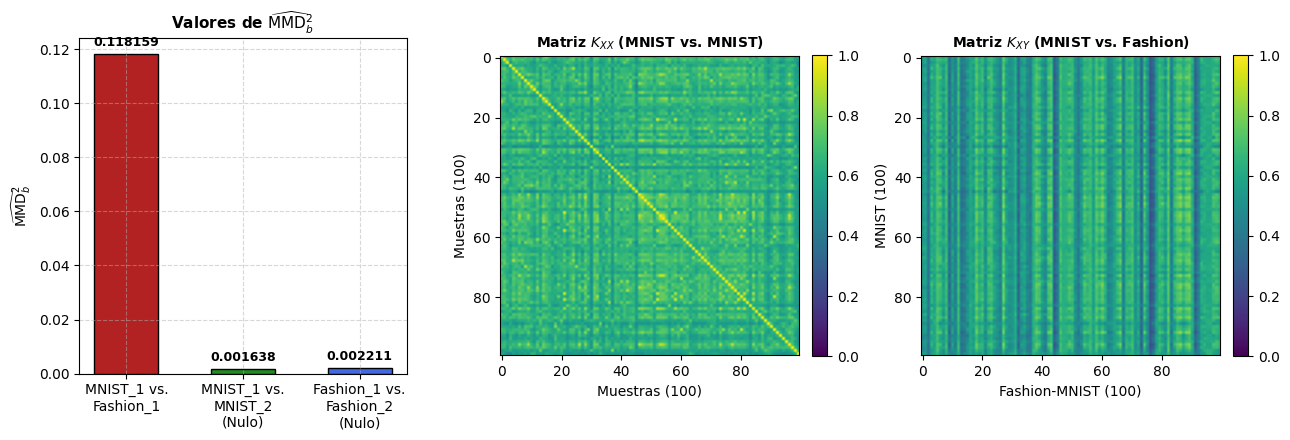

In [15]:
# 7. Visualización gráfica (Estilo de clase del profesor)
fig = plt.figure(figsize=(13, 4.5))

# Subplot 1: Gráfico de barras de MMD^2
ax1 = fig.add_subplot(1, 3, 1)
casos = ['MNIST_1 vs.\nFashion_1', 'MNIST_1 vs.\nMNIST_2\n(Nulo)', 'Fashion_1 vs.\nFashion_2\n(Nulo)']
valores = [mmd_cross, mmd_null_m, mmd_null_f]
colores = ['firebrick', 'forestgreen', 'royalblue']
barras = ax1.bar(casos, valores, color=colores, width=0.55, edgecolor='black')
ax1.set_title(r"Valores de $\widehat{\mathrm{MMD}}_b^2$", fontsize=11, fontweight='bold')
ax1.set_ylabel(r"$\widehat{\mathrm{MMD}}_b^2$")
ax1.grid(True, linestyle='--', alpha=0.5)
for bar in barras:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.003, f"{h:.6f}", ha='center', fontsize=9, fontweight='bold')

# Subplot 2: Matriz K_XX (primeras 100 muestras)
ax2 = fig.add_subplot(1, 3, 2)
im1 = ax2.imshow(K_XX[:100, :100], cmap='viridis', vmin=0, vmax=1)
ax2.set_title(r"Matriz $K_{XX}$ (MNIST vs. MNIST)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Muestras (100)")
ax2.set_ylabel("Muestras (100)")
plt.colorbar(im1, ax=ax2, fraction=0.046, pad=0.04)

# Subplot 3: Matriz K_XY cruzada (primeras 100 muestras)
ax3 = fig.add_subplot(1, 3, 3)
im2 = ax3.imshow(K_XY[:100, :100], cmap='viridis', vmin=0, vmax=1)
ax3.set_title(r"Matriz $K_{XY}$ (MNIST vs. Fashion)", fontsize=10, fontweight='bold')
ax3.set_xlabel("Fashion-MNIST (100)")
ax3.set_ylabel("MNIST (100)")
plt.colorbar(im2, ax=ax3, fraction=0.046, pad=0.04)

plt.tight_layout()
print("\nMostrando gráficos de resultados...")
plt.show()

In [ ]:
# 8. Visualización Animada: Interpretación Geométrica del RKHS y MMD
from IPython.display import Image
Image(filename="animacion_rkhs_mmd.gif")
